# Unit18_Example_Molecular_Solubility | 以 GNN 預測分子水溶解度

本 Notebook 使用公開的 **ESOL (Delaney) 水溶解度資料集**（1128 個有機分子），以 TensorFlow/Keras **從零實作一個圖卷積網路(GCN)**，直接從**分子結構**預測其水溶解度 $\log S$ （graph-level regression）。

這是圖神經網路在**化工/化學**領域最具代表性的應用之一：**定量結構-性質關係 (QSPR)**。水溶解度是製程設計、配方、分離純化與環境評估的關鍵物性。

## 目標
- 以 RDKit 將 **SMILES** 字串轉換成**分子圖**（原子為節點、化學鍵為邊）
- 設計原子特徵向量（原子種類、度、雜化、芳香性、氫數、是否在環上）
- 以 padding 批次化不同大小的分子圖，從零實作 **batched GCN 層**
- 以 **masked mean pooling** 讀出整個分子的表示，接 MLP 輸出 $\log S$
- 與 **Delaney 原始 ESOL 線性模型** 及 **描述子 + Ridge 回歸** 比較

## 資料來源
- Delaney, J. S. (2004). "ESOL: Estimating Aqueous Solubility Directly from Molecular Structure." *J. Chem. Inf. Comput. Sci.* 44(3), 1000-1005.
- 透過 MoleculeNet / DeepChem 公開提供：`delaney-processed.csv`


---
### 0. 環境設定
- 本範例使用 ESOL 水溶解度資料集，程式會自動下載。
- 需要 `rdkit` 套件將 SMILES 轉為分子圖；資料量小，CPU 即可完成訓練。

In [1]:
from pathlib import Path
import tensorflow as tf
import os

# ========================================
# 路徑設定 (兼容 Colab 與 Local)
# ========================================
UNIT_OUTPUT_DIR = 'P4_Unit18_Example_Molecular_Solubility'
SOURCE_DATA_DIR = 'esol'

try:
    from google.colab import drive
    IN_COLAB = True
    print("✓ 偵測到 Colab 環境，準備掛載 Google Drive...")
    drive.mount('/content/drive', force_remount=True)
except ImportError:
    IN_COLAB = False
    print("✓ 偵測到 Local 環境")

if IN_COLAB:
    shortcut_path = '/content/ChemE-3590'
    try:
        os.remove(shortcut_path)
    except FileNotFoundError:
        pass
    source_path = Path('/content/drive/My Drive/Colab Notebooks/ChemE-3590')
    os.symlink(source_path, shortcut_path)
    NOTEBOOK_DIR = Path(shortcut_path) / 'Part_4' / 'Unit18'
else:
    NOTEBOOK_DIR = Path.cwd()

OUTPUT_DIR = NOTEBOOK_DIR / 'outputs' / UNIT_OUTPUT_DIR
DATA_DIR = NOTEBOOK_DIR / 'data' / SOURCE_DATA_DIR
MODEL_DIR = OUTPUT_DIR / 'models'
FIG_DIR = OUTPUT_DIR / 'figs'

for d in (NOTEBOOK_DIR, OUTPUT_DIR, DATA_DIR, MODEL_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f"\n✓ Notebook工作目錄: {NOTEBOOK_DIR}")
print(f"✓ 數據來源目錄: {DATA_DIR}")
print(f"✓ 結果輸出目錄: {OUTPUT_DIR}")

# ========================================
# 檢查 GPU 狀態
# ========================================
print(f"\nTensorFlow Version: {tf.__version__}")
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"✓ 偵測到 GPU：{gpus[0].name}")
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
else:
    print("△ 未偵測到 GPU，將使用 CPU(本範例資料量小，CPU 即可完成)。")


✓ 偵測到 Local 環境

✓ Notebook工作目錄: d:\MyGit\ChemE-3590\Part_4\Unit18
✓ 數據來源目錄: d:\MyGit\ChemE-3590\Part_4\Unit18\data\esol
✓ 結果輸出目錄: d:\MyGit\ChemE-3590\Part_4\Unit18\outputs\P4_Unit18_Example_Molecular_Solubility

TensorFlow Version: 2.10.1
✓ 偵測到 GPU：/physical_device:GPU:0


---
### 數據下載
自動下載 ESOL (Delaney) 水溶解度資料集 CSV。

In [2]:
import urllib.request

ESOL_URL = "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/delaney-processed.csv"
csv_path = DATA_DIR / "delaney-processed.csv"

if not csv_path.exists():
    print(f"正在下載 ESOL 資料集至: {csv_path} ...")
    urllib.request.urlretrieve(ESOL_URL, str(csv_path))
    print("下載完成！")
else:
    print(f"檔案已存在: {csv_path}")


檔案已存在: d:\MyGit\ChemE-3590\Part_4\Unit18\data\esol\delaney-processed.csv


---
### 1. 導入必要套件

In [3]:
# 基礎套件
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# RDKit (化學資訊學: SMILES -> 分子圖)
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Draw import rdMolDraw2D
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print(f"TensorFlow版本: {tf.__version__}")
print(f"Keras版本: {keras.__version__}")
import rdkit
print(f"RDKit版本: {rdkit.__version__}")

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
plt.rcParams['axes.unicode_minus'] = False


TensorFlow版本: 2.10.1
Keras版本: 2.10.0
RDKit版本: 2026.09.2


---
### 2. 載入與探索資料

ESOL 資料集每一列是一個分子，包含 SMILES 字串、實測水溶解度 $\log S$ （mol/L 取以 10 為底的對數），以及 Delaney 原始論文用線性模型預測的 $\log S$ 與數個分子描述子。

In [4]:
df = pd.read_csv(csv_path)
print(f"資料集大小: {df.shape[0]} 個分子, {df.shape[1]} 個欄位\n")
print("欄位名稱:")
for c in df.columns:
    print(f"  - {c}")

# 重新命名關鍵欄位，方便使用
df = df.rename(columns={
    'measured log solubility in mols per litre': 'logS',
    'ESOL predicted log solubility in mols per litre': 'logS_ESOL',
})
print("\n前 3 列:")
display_cols = ['Compound ID', 'smiles', 'logS', 'logS_ESOL', 'Molecular Weight']
print(df[display_cols].head(3).to_string(index=False))

print(f"\n實測 logS 統計: min={df['logS'].min():.2f}, max={df['logS'].max():.2f}, "
      f"mean={df['logS'].mean():.2f}, std={df['logS'].std():.2f}")


資料集大小: 1128 個分子, 10 個欄位

欄位名稱:
  - Compound ID
  - ESOL predicted log solubility in mols per litre
  - Minimum Degree
  - Molecular Weight
  - Number of H-Bond Donors
  - Number of Rings
  - Number of Rotatable Bonds
  - Polar Surface Area
  - measured log solubility in mols per litre
  - smiles

前 3 列:
Compound ID                                                 smiles  logS  logS_ESOL  Molecular Weight
  Amigdalin OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)C(O)C3O  -0.77     -0.974           457.432
   Fenfuram                                 Cc1occc1C(=O)Nc2ccccc2 -3.30     -2.885           201.225
     citral                                   CC(C)=CCCC(C)=CC(=O) -2.06     -2.579           152.237

實測 logS 統計: min=-11.60, max=1.58, mean=-3.05, std=2.10


### 2.1 目標變數分佈

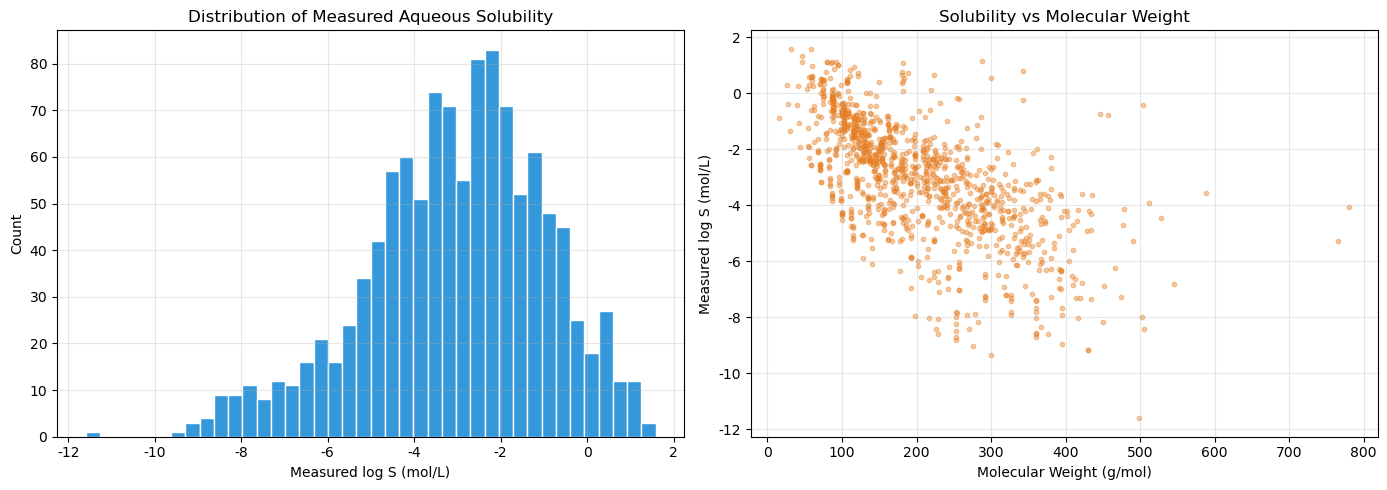

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['logS'], bins=40, color='#3498db', edgecolor='white')
axes[0].set_title('Distribution of Measured Aqueous Solubility')
axes[0].set_xlabel('Measured log S (mol/L)')
axes[0].set_ylabel('Count')
axes[0].grid(True, alpha=0.3)

axes[1].scatter(df['Molecular Weight'], df['logS'], s=10, alpha=0.4, color='#e67e22')
axes[1].set_title('Solubility vs Molecular Weight')
axes[1].set_xlabel('Molecular Weight (g/mol)')
axes[1].set_ylabel('Measured log S (mol/L)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'target_distribution.png', dpi=120, bbox_inches='tight')
plt.show()


---
### 2.2 從 SMILES 到分子圖

GNN 的輸入是圖。我們用 RDKit 把每個 SMILES 解析成分子，並建立：

- **節點特徵矩陣** $X \in \mathbb{R}^{N \times F}$ ：每個原子一個特徵向量
- **鄰接矩陣** $A \in \mathbb{R}^{N \times N}$ ：化學鍵連接關係

每個原子的特徵包含：原子種類（one-hot）、度(degree)、形式電荷、雜化狀態、是否芳香、連接氫數、是否在環上。

In [6]:
from rdkit.Chem.rdchem import HybridizationType

# 常見原子種類 (ESOL 以有機分子為主)
ATOM_SYMBOLS = ['C', 'N', 'O', 'F', 'S', 'Cl', 'Br', 'I', 'P']
HYBRIDIZATIONS = [HybridizationType.SP, HybridizationType.SP2, HybridizationType.SP3]

def _onehot(value, choices):
    return [1 if value == c else 0 for c in choices]

def atom_features(atom):
    """將一個 RDKit 原子轉為特徵向量 (維度 F)"""
    sym = atom.GetSymbol()
    feats = []
    feats += _onehot(sym, ATOM_SYMBOLS)                 # 9  原子種類
    feats += [1 if sym not in ATOM_SYMBOLS else 0]      # 1  其他原子
    feats += _onehot(atom.GetDegree(), [0, 1, 2, 3, 4, 5])   # 6  度
    feats += [atom.GetFormalCharge()]                   # 1  形式電荷
    feats += _onehot(atom.GetHybridization(), HYBRIDIZATIONS) # 3  雜化
    feats += [1 if atom.GetIsAromatic() else 0]         # 1  芳香性
    feats += _onehot(atom.GetTotalNumHs(), [0, 1, 2, 3, 4])  # 5  連接氫數
    feats += [1 if atom.IsInRing() else 0]              # 1  是否在環上
    return np.array(feats, dtype='float32')

def smiles_to_graph(smiles):
    """SMILES -> (節點特徵矩陣 X, 鄰接矩陣 A)"""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    n = mol.GetNumAtoms()
    X = np.stack([atom_features(a) for a in mol.GetAtoms()], axis=0)
    A = np.zeros((n, n), dtype='float32')
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        A[i, j] = 1.0
        A[j, i] = 1.0
    return X, A

# 測試特徵維度
_X, _A = smiles_to_graph('CCO')  # 乙醇
F = _X.shape[1]
print(f"原子特徵維度 F = {F}")
print(f"乙醇 (CCO): {_X.shape[0]} 個原子, 鄰接矩陣 shape = {_A.shape}")
print(f"乙醇鄰接矩陣:\n{_A}")


原子特徵維度 F = 27
乙醇 (CCO): 3 個原子, 鄰接矩陣 shape = (3, 3)
乙醇鄰接矩陣:
[[0. 1. 0.]
 [1. 0. 1.]
 [0. 1. 0.]]


### 2.3 視覺化一個分子及其圖表示

以阿斯匹靈 (Aspirin) 為例，展示分子結構與對應的鄰接矩陣。

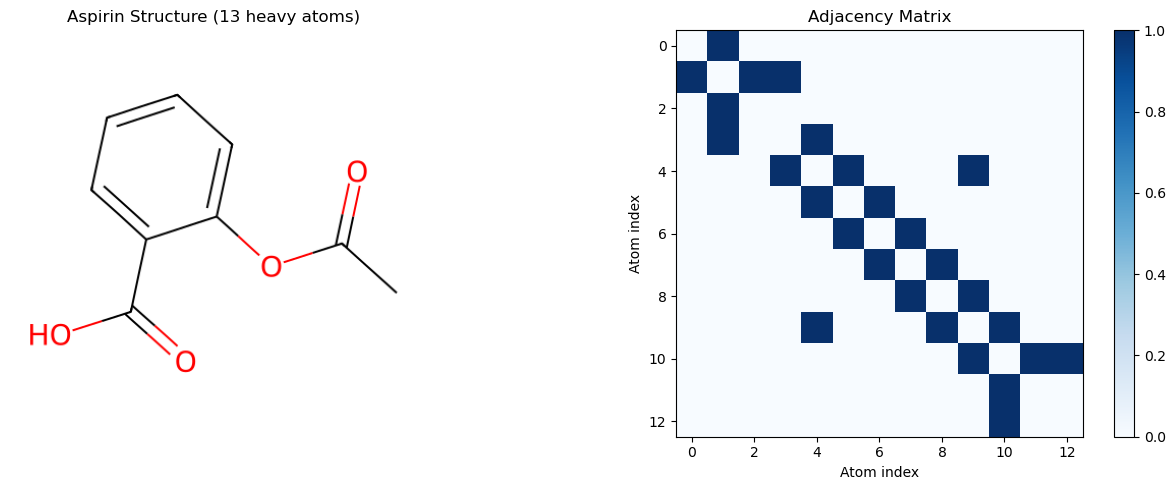

Aspirin: 13 個重原子, 13 條鍵


In [7]:
aspirin_smiles = 'CC(=O)Oc1ccccc1C(=O)O'
mol = Chem.MolFromSmiles(aspirin_smiles)
Xa, Aa = smiles_to_graph(aspirin_smiles)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 左: 分子結構圖
d = rdMolDraw2D.MolDraw2DCairo(400, 400)
d.DrawMolecule(mol)
d.FinishDrawing()
with open(FIG_DIR / 'aspirin_mol.png', 'wb') as f:
    f.write(d.GetDrawingText())
axes[0].imshow(plt.imread(FIG_DIR / 'aspirin_mol.png'))
axes[0].axis('off')
axes[0].set_title(f'Aspirin Structure ({mol.GetNumAtoms()} heavy atoms)')

# 右: 鄰接矩陣
im = axes[1].imshow(Aa, cmap='Blues')
axes[1].set_title('Adjacency Matrix')
axes[1].set_xlabel('Atom index')
axes[1].set_ylabel('Atom index')
plt.colorbar(im, ax=axes[1], fraction=0.046)

plt.tight_layout()
plt.savefig(FIG_DIR / 'aspirin_graph.png', dpi=120, bbox_inches='tight')
plt.show()

print(f"Aspirin: {mol.GetNumAtoms()} 個重原子, {int(Aa.sum()/2)} 條鍵")


---
### 3. 特徵化整個資料集並進行 Padding

不同分子的原子數不同，無法直接堆成一個張量。常見做法是將所有分子的節點特徵與鄰接矩陣 **padding(補零)** 到相同的最大原子數 $M$ ，並用一個 **節點遮罩(mask)** 標記哪些是真實原子、哪些是填充的。

In [8]:
# 先特徵化所有分子，取得最大原子數
graphs = []
targets = []
for smi, y in zip(df['smiles'], df['logS']):
    g = smiles_to_graph(smi)
    if g is not None:
        graphs.append(g)
        targets.append(y)

MAX_ATOMS = max(X.shape[0] for X, A in graphs)
n_mol = len(graphs)
print(f"成功轉換 {n_mol} 個分子")
print(f"最大原子數 MAX_ATOMS = {MAX_ATOMS}")

# Padding 到 (n_mol, MAX_ATOMS, F) 與 (n_mol, MAX_ATOMS, MAX_ATOMS)
X_all = np.zeros((n_mol, MAX_ATOMS, F), dtype='float32')
A_all = np.zeros((n_mol, MAX_ATOMS, MAX_ATOMS), dtype='float32')
mask_all = np.zeros((n_mol, MAX_ATOMS, 1), dtype='float32')

for k, (X, A) in enumerate(graphs):
    n = X.shape[0]
    X_all[k, :n, :] = X
    A_all[k, :n, :n] = A
    mask_all[k, :n, 0] = 1.0

y_all = np.array(targets, dtype='float32').reshape(-1, 1)
print(f"X_all shape = {X_all.shape}")
print(f"A_all shape = {A_all.shape}")
print(f"mask_all shape = {mask_all.shape}")
print(f"y_all shape = {y_all.shape}")


成功轉換 1128 個分子
最大原子數 MAX_ATOMS = 55
X_all shape = (1128, 55, 27)
A_all shape = (1128, 55, 55)
mask_all shape = (1128, 55, 1)
y_all shape = (1128, 1)


### 3.1 建立正規化鄰接矩陣（批次）

對每個分子計算 GCN 的正規化鄰接矩陣（僅對真實原子加自連接）：

$$
\tilde{A} = A + I_{\text{real}}, \quad \hat{A} = \tilde{D}^{-1/2}\, \tilde{A}\, \tilde{D}^{-1/2}
$$

In [9]:
def normalize_adjacency(A, mask):
    """對單一分子: A_hat = D^{-1/2} (A + I_real) D^{-1/2}"""
    M = A.shape[0]
    self_loop = np.diag(mask[:, 0])              # 僅真實原子有自連接
    A_tilde = A + self_loop
    deg = A_tilde.sum(axis=1)
    d_inv_sqrt = np.zeros_like(deg)
    nz = deg > 0
    d_inv_sqrt[nz] = 1.0 / np.sqrt(deg[nz])
    D_inv_sqrt = np.diag(d_inv_sqrt)
    return (D_inv_sqrt @ A_tilde @ D_inv_sqrt).astype('float32')

A_hat_all = np.stack([normalize_adjacency(A_all[k], mask_all[k]) for k in range(n_mol)], axis=0)
print(f"A_hat_all shape = {A_hat_all.shape}")
print(f"檢查第一個分子 A_hat 對稱: {np.allclose(A_hat_all[0], A_hat_all[0].T)}")


A_hat_all shape = (1128, 55, 55)
檢查第一個分子 A_hat 對稱: True


---
### 4. 資料分割與目標標準化

以 80/20 分割訓練集與測試集。回歸目標 $\log S$ 進行標準化（z-score）以穩定訓練，評估時再還原。

In [10]:
idx = np.arange(n_mol)
idx_train, idx_test = train_test_split(idx, test_size=0.2, random_state=SEED)

Xtr, Xte = X_all[idx_train], X_all[idx_test]
Atr, Ate = A_hat_all[idx_train], A_hat_all[idx_test]
Mtr, Mte = mask_all[idx_train], mask_all[idx_test]
ytr_raw, yte_raw = y_all[idx_train], y_all[idx_test]

# 標準化目標
y_scaler = StandardScaler()
ytr = y_scaler.fit_transform(ytr_raw).astype('float32')
yte = y_scaler.transform(yte_raw).astype('float32')

print(f"訓練集: {len(idx_train)} 個分子")
print(f"測試集: {len(idx_test)} 個分子")
print(f"目標標準化前 mean={ytr_raw.mean():.3f}, std={ytr_raw.std():.3f}")


訓練集: 902 個分子
測試集: 226 個分子
目標標準化前 mean=-3.045, std=2.075


---
### 5. 從零實作 batched GCN 層

批次化的 GCN 一層：對每個分子計算

$$
H' = \sigma\left( \hat{A}\, (H W) + b \right)
$$

其中 $H$ 的形狀為 $(B, M, F)$ ， $\hat{A}$ 為 $(B, M, M)$ 。特徵轉換 $HW$ 用 `einsum('bnf,fu->bnu')`，鄰居聚合 $\hat{A}H$ 用批次矩陣乘法 `tf.matmul`。

In [11]:
class GCNLayer(layers.Layer):
    """Batched 圖卷積層: H' = activation( A_hat @ (H @ W) + b )"""

    def __init__(self, units, activation=None, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.activation = keras.activations.get(activation)

    def build(self, input_shape):
        feat_dim = int(input_shape[0][-1])
        self.w = self.add_weight(name='w', shape=(feat_dim, self.units),
                                 initializer='glorot_uniform', trainable=True)
        self.b = self.add_weight(name='b', shape=(self.units,),
                                 initializer='zeros', trainable=True)

    def call(self, inputs):
        H, A_hat = inputs
        support = tf.einsum('bnf,fu->bnu', H, self.w) + self.b  # 特徵轉換 (B,M,units)
        out = tf.matmul(A_hat, support)                        # 鄰居聚合 (B,M,units)
        return self.activation(out)


def masked_mean_pool(args):
    """masked mean pooling: 只對真實原子取平均 -> 圖層級表示"""
    H, mask = args
    summed = tf.reduce_sum(H * mask, axis=1)        # (B, units)
    count = tf.reduce_sum(mask, axis=1)             # (B, 1)
    return summed / (count + 1e-8)

print("GCNLayer 與 masked_mean_pool 已定義。")


GCNLayer 與 masked_mean_pool 已定義。


---
### 6. 建立 GCN 回歸模型

堆疊兩層 GCN，每層後以節點遮罩清除填充節點的值，再以 masked mean pooling 得到分子層級表示，最後接 MLP 輸出 $\log S$ 。

In [12]:
def build_gcn_regressor(max_atoms, n_features, hidden=64):
    X_in = keras.Input(shape=(max_atoms, n_features), name='node_features')
    A_in = keras.Input(shape=(max_atoms, max_atoms), name='norm_adjacency')
    M_in = keras.Input(shape=(max_atoms, 1), name='node_mask')

    h = GCNLayer(hidden, activation='relu')([X_in, A_in])
    h = layers.Multiply()([h, M_in])                 # 清除填充節點
    h = GCNLayer(hidden, activation='relu')([h, A_in])
    h = layers.Multiply()([h, M_in])

    pooled = layers.Lambda(masked_mean_pool, name='readout')([h, M_in])
    z = layers.Dense(64, activation='relu')(pooled)
    z = layers.Dropout(0.2)(z)
    out = layers.Dense(1, name='logS')(z)

    return keras.Model(inputs=[X_in, A_in, M_in], outputs=out)

model = build_gcn_regressor(MAX_ATOMS, F, hidden=64)
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='mse', metrics=['mae'])
model.summary()


Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 node_features (InputLayer)     [(None, 55, 27)]     0           []                               
                                                                                                  
 norm_adjacency (InputLayer)    [(None, 55, 55)]     0           []                               
                                                                                                  
 gcn_layer (GCNLayer)           (None, 55, 64)       1792        ['node_features[0][0]',          
                                                                  'norm_adjacency[0][0]']         
                                                                                                  
 node_mask (InputLayer)         [(None, 55, 1)]      0           []                           

---
### 7. 訓練模型

以 MSE 損失訓練，使用 EarlyStopping 避免過擬合。輸入為 `[節點特徵, 正規化鄰接矩陣, 節點遮罩]`。

In [13]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=30,
                                  restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                      patience=15, min_lr=1e-5),
]

history = model.fit(
    [Xtr, Atr, Mtr], ytr,
    validation_split=0.15,
    epochs=200,
    batch_size=32,
    callbacks=callbacks,
    verbose=0,
)

print(f"訓練完成，共 {len(history.history['loss'])} 個 epoch")
print(f"最終訓練 loss = {history.history['loss'][-1]:.4f}")
print(f"最終驗證 loss = {history.history['val_loss'][-1]:.4f}")


訓練完成，共 193 個 epoch
最終訓練 loss = 0.0670
最終驗證 loss = 0.1506


### 7.1 訓練曲線

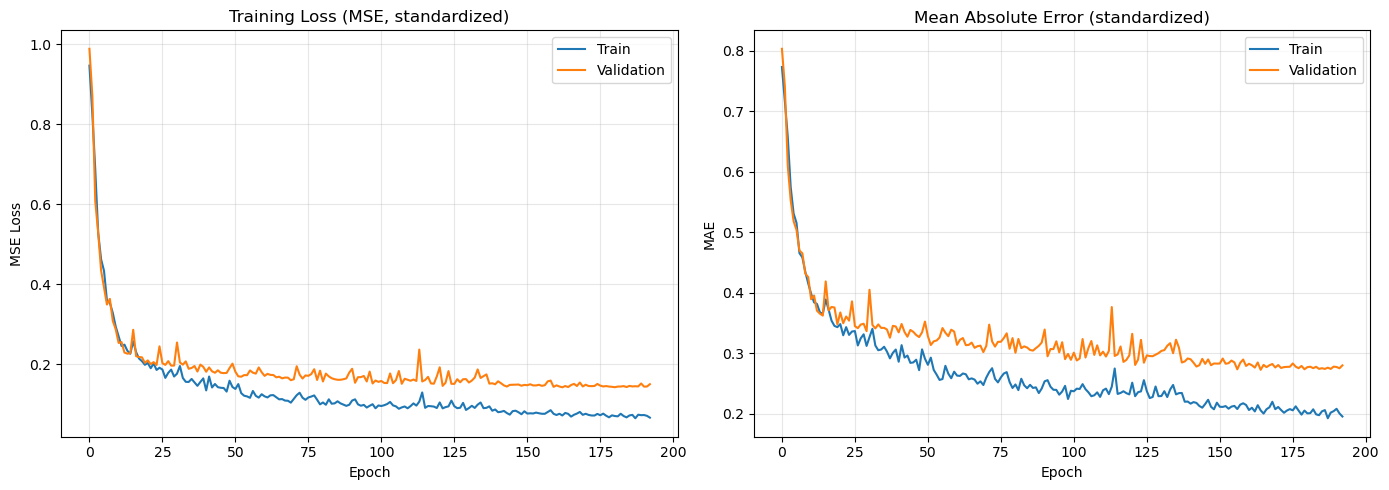

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['loss'], label='Train')
axes[0].plot(history.history['val_loss'], label='Validation')
axes[0].set_title('Training Loss (MSE, standardized)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['mae'], label='Train')
axes[1].plot(history.history['val_mae'], label='Validation')
axes[1].set_title('Mean Absolute Error (standardized)')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MAE')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'training_curves.png', dpi=120, bbox_inches='tight')
plt.show()


---
### 8. 評估與基線比較

我們以三種方法在**相同測試集**上比較預測實測 $\log S$ 的表現：

1. **GCN**（本範例，直接從分子結構學習）
2. **Delaney ESOL 線性模型**（原始論文，資料集內附的預測值）
3. **描述子 + Ridge 回歸**（用分子量、氫鍵供體數、環數等描述子）

評估指標： $R^2$ 、MAE、RMSE。

In [15]:
def regression_metrics(y_true, y_pred):
    return (r2_score(y_true, y_pred),
            mean_absolute_error(y_true, y_pred),
            np.sqrt(mean_squared_error(y_true, y_pred)))

# --- 1. GCN 預測 (還原標準化) ---
gcn_pred_std = model.predict([Xte, Ate, Mte], verbose=0)
gcn_pred = y_scaler.inverse_transform(gcn_pred_std).ravel()
y_true = yte_raw.ravel()
r2_gcn, mae_gcn, rmse_gcn = regression_metrics(y_true, gcn_pred)

# --- 2. Delaney ESOL 線性模型 (資料集內附預測) ---
esol_pred = df['logS_ESOL'].values[idx_test]
r2_esol, mae_esol, rmse_esol = regression_metrics(y_true, esol_pred)

# --- 3. 描述子 + Ridge ---
desc_cols = ['Molecular Weight', 'Number of H-Bond Donors', 'Number of Rings',
             'Number of Rotatable Bonds', 'Polar Surface Area', 'Minimum Degree']
Dtr = df[desc_cols].values[idx_train]
Dte = df[desc_cols].values[idx_test]
desc_scaler = StandardScaler()
ridge = Ridge(alpha=1.0)
ridge.fit(desc_scaler.fit_transform(Dtr), ytr_raw.ravel())
ridge_pred = ridge.predict(desc_scaler.transform(Dte))
r2_ridge, mae_ridge, rmse_ridge = regression_metrics(y_true, ridge_pred)

results = pd.DataFrame({
    'Model': ['GCN (graph)', 'Delaney ESOL (linear)', 'Descriptors + Ridge'],
    'R2': [r2_gcn, r2_esol, r2_ridge],
    'MAE': [mae_gcn, mae_esol, mae_ridge],
    'RMSE': [rmse_gcn, rmse_esol, rmse_ridge],
})
print("測試集表現比較 (預測實測 log S):\n")
print(results.to_string(index=False, float_format=lambda x: f'{x:.3f}'))


測試集表現比較 (預測實測 log S):

                Model    R2   MAE  RMSE
          GCN (graph) 0.905 0.481 0.670
Delaney ESOL (linear) 0.807 0.708 0.956
  Descriptors + Ridge 0.696 0.892 1.199


### 8.1 Parity Plot（預測值 vs 實測值）

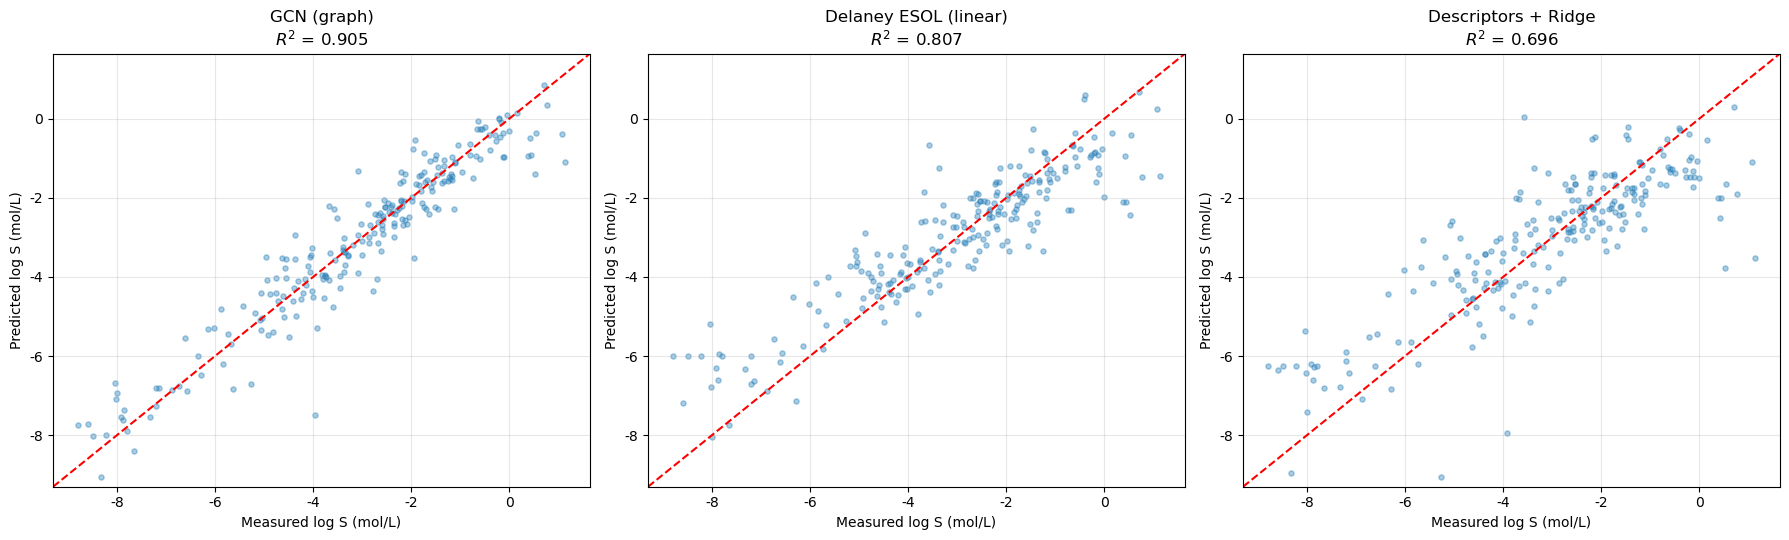

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
preds = [('GCN (graph)', gcn_pred, r2_gcn),
         ('Delaney ESOL (linear)', esol_pred, r2_esol),
         ('Descriptors + Ridge', ridge_pred, r2_ridge)]
lo, hi = y_true.min() - 0.5, y_true.max() + 0.5

for ax, (name, pred, r2) in zip(axes, preds):
    ax.scatter(y_true, pred, s=14, alpha=0.4, color='#2980b9')
    ax.plot([lo, hi], [lo, hi], 'r--', lw=1.5)
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_title(f'{name}\n$R^2$ = {r2:.3f}')
    ax.set_xlabel('Measured log S (mol/L)')
    ax.set_ylabel('Predicted log S (mol/L)')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'parity_comparison.png', dpi=120, bbox_inches='tight')
plt.show()


### 8.2 範例分子的預測結果

展示幾個測試集分子的結構、實測與 GCN 預測的溶解度。

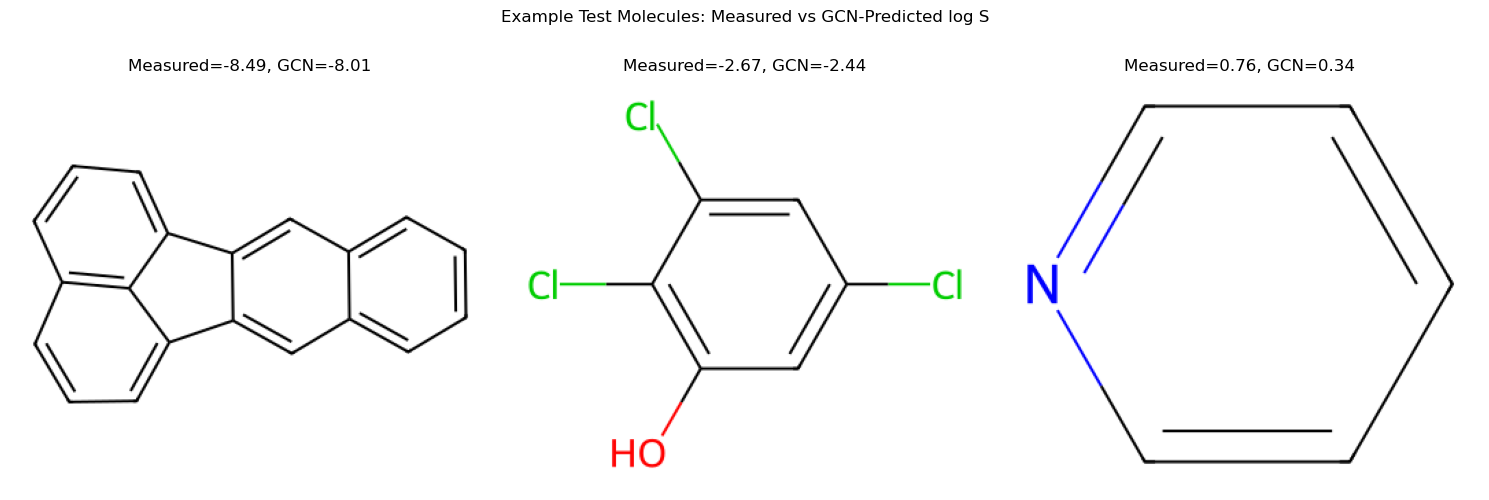

In [17]:
order = np.argsort(y_true)
pick = [order[2], order[len(order)//2], order[-3]]  # 低/中/高溶解度各一

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, p in zip(axes, pick):
    smi = df['smiles'].values[idx_test][p]
    mol = Chem.MolFromSmiles(smi)
    d = rdMolDraw2D.MolDraw2DCairo(350, 300)
    d.DrawMolecule(mol)
    d.FinishDrawing()
    tmp = FIG_DIR / f'_tmp_mol_{p}.png'
    with open(tmp, 'wb') as fh:
        fh.write(d.GetDrawingText())
    ax.imshow(plt.imread(tmp))
    ax.axis('off')
    ax.set_title(f'Measured={y_true[p]:.2f}, GCN={gcn_pred[p]:.2f}')
    os.remove(tmp)

plt.suptitle('Example Test Molecules: Measured vs GCN-Predicted log S', y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / 'example_molecules.png', dpi=120, bbox_inches='tight')
plt.show()


---
### 8.3 殘差分析：模型在哪裡出錯？

單一 $R^2$ 無法說明模型**在哪些分子上出錯**。回歸任務的標準診斷是**殘差分析**：把預測誤差 $r_i = \hat{y}_i - y_i$ 對預測值作圖，並檢視誤差分佈。

- **理想情況**：殘差應隨機散佈在 0 附近、無明顯趨勢（同質變異、無系統性偏差）。
- **誤差最大的分子**：找出 GCN 預測最離譜的幾個分子，往往能揭露模型的**盲點**（例如訓練集中罕見的結構、極端溶解度）。


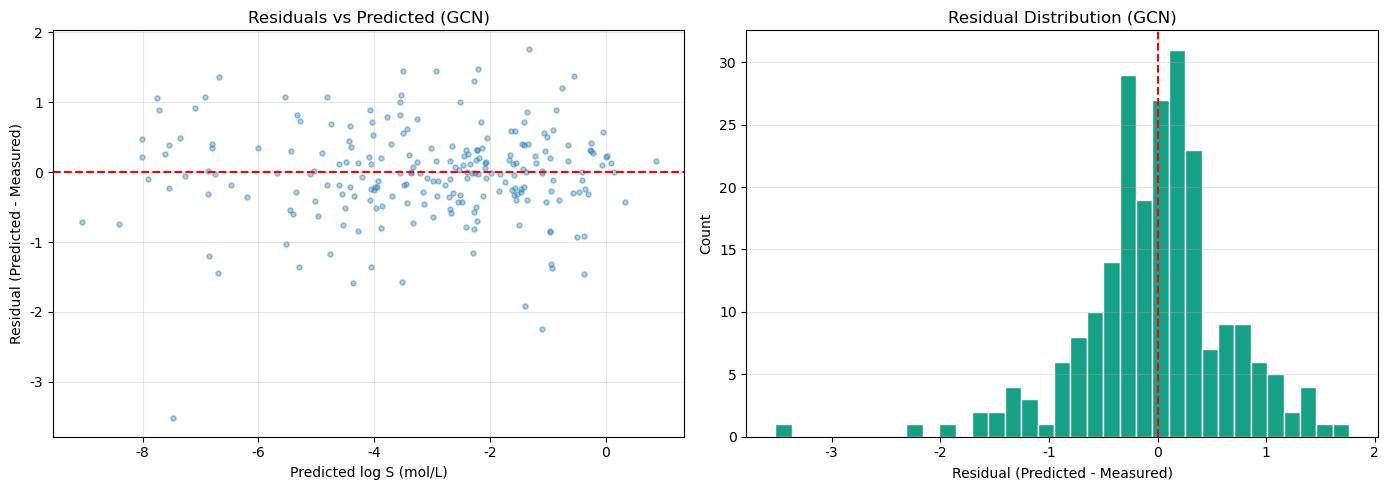

殘差平均 = -0.024 (接近 0 表示無系統性偏差)
殘差標準差 = 0.669
誤差在 ±0.7 log 單位內的比例 = 74.8%
誤差在 ±1.0 log 單位內的比例 = 87.2%


In [18]:
residuals = gcn_pred - y_true

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 左: 殘差 vs 預測值
axes[0].scatter(gcn_pred, residuals, s=14, alpha=0.4, color='#2980b9')
axes[0].axhline(0, color='r', ls='--', lw=1.5)
axes[0].set_title('Residuals vs Predicted (GCN)')
axes[0].set_xlabel('Predicted log S (mol/L)')
axes[0].set_ylabel('Residual (Predicted - Measured)')
axes[0].grid(True, alpha=0.3)

# 右: 殘差分佈
axes[1].hist(residuals, bins=35, color='#16a085', edgecolor='white')
axes[1].axvline(0, color='r', ls='--', lw=1.5)
axes[1].set_title('Residual Distribution (GCN)')
axes[1].set_xlabel('Residual (Predicted - Measured)')
axes[1].set_ylabel('Count')
axes[1].grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'residual_analysis.png', dpi=120, bbox_inches='tight')
plt.show()

print(f"殘差平均 = {residuals.mean():+.3f} (接近 0 表示無系統性偏差)")
print(f"殘差標準差 = {residuals.std():.3f}")
print(f"誤差在 ±0.7 log 單位內的比例 = {100*np.mean(np.abs(residuals) <= 0.7):.1f}%")
print(f"誤差在 ±1.0 log 單位內的比例 = {100*np.mean(np.abs(residuals) <= 1.0):.1f}%")


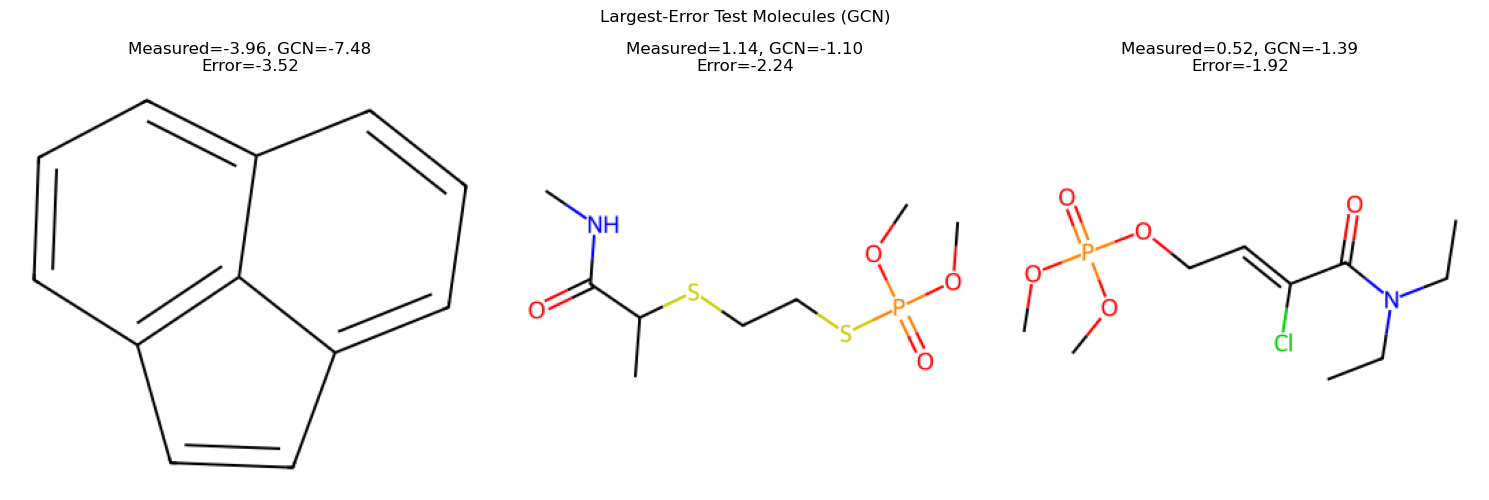

C1=Cc2cccc3cccc1c23                      實測=-3.96, GCN=-7.48, 誤差=-3.52
CNC(=O)C(C)SCCSP(=O)(OC)(OC)             實測=+1.14, GCN=-1.10, 誤差=-2.24
CCN(CC)C(=O)C(=CCOP(=O)(OC)OC)Cl         實測=+0.52, GCN=-1.39, 誤差=-1.92


In [19]:
# 誤差最大的 3 個分子 (|殘差| 最大)
worst = np.argsort(np.abs(residuals))[::-1][:3]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, p in zip(axes, worst):
    smi = df['smiles'].values[idx_test][p]
    mol = Chem.MolFromSmiles(smi)
    d = rdMolDraw2D.MolDraw2DCairo(350, 300)
    d.DrawMolecule(mol); d.FinishDrawing()
    tmp = FIG_DIR / f'_w_{p}.png'
    with open(tmp, 'wb') as fh:
        fh.write(d.GetDrawingText())
    ax.imshow(plt.imread(tmp)); ax.axis('off')
    ax.set_title(f'Measured={y_true[p]:.2f}, GCN={gcn_pred[p]:.2f}\nError={residuals[p]:+.2f}')
    os.remove(tmp)
plt.suptitle('Largest-Error Test Molecules (GCN)', y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / 'worst_molecules.png', dpi=120, bbox_inches='tight')
plt.show()

for p in worst:
    print(f"{df['smiles'].values[idx_test][p]:40s} "
          f"實測={y_true[p]:+.2f}, GCN={gcn_pred[p]:+.2f}, 誤差={residuals[p]:+.2f}")


---
### 8.4 與圖注意力網路 (GAT) 的對照

本範例用的 **GCN** 以**固定**的正規化鄰接矩陣聚合鄰居。另一個經典架構 **GAT (圖注意力網路)** 則用**可學習的注意力係數** $\alpha_{ij}$ 自適應加權鄰居：

$$
h_i' = \sigma\left( \sum_{j \in \mathcal{N}(i) \cup \{i\}} \alpha_{ij}\, W h_j \right)
$$

我們以**相同的資料切分、標準化與訓練設定**訓練一個 GAT 回歸模型（第一層 4 個注意力頭、串接成 64 維），只差在聚合方式，藉此公平比較兩種圖架構。

> [!NOTE]
> GAT 使用**含自連接的二元鄰接矩陣** $A + I_{\mathrm{real}}$ （注意力在「鄰居 + 自身」間計算），與 GCN 使用正規化鄰接矩陣 $\hat{A}$ 不同。


In [20]:
class GATLayer(layers.Layer):
    """Batched 多頭圖注意力層 (GAT)。"""
    def __init__(self, units, heads=4, concat=True, activation='elu',
                 leaky_slope=0.2, **kwargs):
        super().__init__(**kwargs)
        self.units = units; self.heads = heads; self.concat = concat
        self.activation = keras.activations.get(activation)
        self.leaky = layers.LeakyReLU(leaky_slope)

    def build(self, input_shape):
        feat_dim = int(input_shape[0][-1])
        self.W = self.add_weight(name='W', shape=(self.heads, feat_dim, self.units),
                                 initializer='glorot_uniform', trainable=True)
        self.a_src = self.add_weight(name='a_src', shape=(self.heads, self.units),
                                     initializer='glorot_uniform', trainable=True)
        self.a_dst = self.add_weight(name='a_dst', shape=(self.heads, self.units),
                                     initializer='glorot_uniform', trainable=True)

    def call(self, inputs):
        H, A = inputs
        Wh = tf.einsum('bnf,hfu->bnhu', H, self.W)
        e_src = tf.einsum('bnhu,hu->bnh', Wh, self.a_src)
        e_dst = tf.einsum('bnhu,hu->bnh', Wh, self.a_dst)
        e = self.leaky(e_src[:, :, None, :] + e_dst[:, None, :, :])
        adj_mask = (A > 0)[:, :, :, None]
        e = tf.where(adj_mask, e, tf.fill(tf.shape(e), -1e9))
        alpha = tf.nn.softmax(e, axis=2)
        out = tf.einsum('bijh,bjhu->bihu', alpha, Wh)
        if self.concat:
            out = tf.reshape(out, tf.concat([tf.shape(out)[:2], [self.heads*self.units]], 0))
        else:
            out = tf.reduce_mean(out, axis=2)
        return self.activation(out)

# GAT 用含自連接的二元鄰接矩陣 (非正規化)
A_self_all = A_all + np.eye(MAX_ATOMS, dtype='float32')[None, :, :] * mask_all
Atr_s, Ate_s = A_self_all[idx_train], A_self_all[idx_test]

def build_gat_regressor(max_atoms, n_features):
    X_in = keras.Input(shape=(max_atoms, n_features), name='node_features')
    A_in = keras.Input(shape=(max_atoms, max_atoms), name='adjacency_self')
    M_in = keras.Input(shape=(max_atoms, 1), name='node_mask')
    h = GATLayer(units=16, heads=4, concat=True)([X_in, A_in])   # -> (B,N,64)
    h = layers.Multiply()([h, M_in])
    h = GATLayer(units=64, heads=1, concat=False)([h, A_in])     # -> (B,N,64)
    h = layers.Multiply()([h, M_in])
    pooled = layers.Lambda(masked_mean_pool, name='readout')([h, M_in])
    z = layers.Dense(64, activation='relu')(pooled)
    z = layers.Dropout(0.2)(z)
    out = layers.Dense(1, name='logS')(z)
    return keras.Model([X_in, A_in, M_in], out)

tf.random.set_seed(SEED)
gat = build_gat_regressor(MAX_ATOMS, F)
gat.compile(optimizer=keras.optimizers.Adam(1e-3), loss='mse', metrics=['mae'])
gat_cb = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=30, restore_best_weights=True),
          keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=15, min_lr=1e-5)]
gat_hist = gat.fit([Xtr, Atr_s, Mtr], ytr, validation_split=0.15, epochs=200,
                   batch_size=32, callbacks=gat_cb, verbose=0)

gat_pred = y_scaler.inverse_transform(gat.predict([Xte, Ate_s, Mte], verbose=0)).ravel()
r2_gat, mae_gat, rmse_gat = regression_metrics(y_true, gat_pred)
print(f"GAT 訓練完成 ({len(gat_hist.history['loss'])} epoch), 參數量 = {gat.count_params()}")

compare = pd.DataFrame({
    'Model': ['GCN (graph conv)', 'GAT (graph attention)',
              'Delaney ESOL (linear)', 'Descriptors + Ridge'],
    'R2':   [r2_gcn, r2_gat, r2_esol, r2_ridge],
    'MAE':  [mae_gcn, mae_gat, mae_esol, mae_ridge],
    'RMSE': [rmse_gcn, rmse_gat, rmse_esol, rmse_ridge],
})
print("\n四方法測試集比較 (預測實測 log S):\n")
print(compare.to_string(index=False, float_format=lambda x: f'{x:.3f}'))


GAT 訓練完成 (200 epoch), 參數量 = 10305

四方法測試集比較 (預測實測 log S):

                Model    R2   MAE  RMSE
     GCN (graph conv) 0.905 0.481 0.670
GAT (graph attention) 0.891 0.504 0.717
Delaney ESOL (linear) 0.807 0.708 0.956
  Descriptors + Ridge 0.696 0.892 1.199


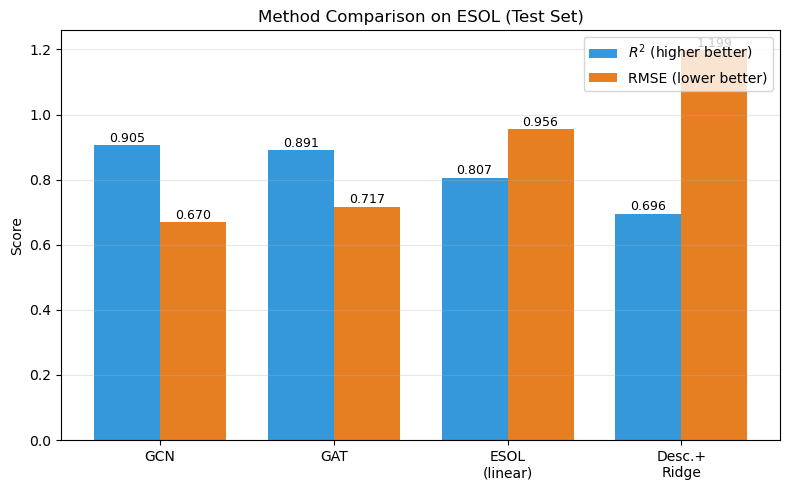

In [21]:
fig, ax = plt.subplots(figsize=(8, 5))
models = ['GCN', 'GAT', 'ESOL\n(linear)', 'Desc.+\nRidge']
r2_vals = [r2_gcn, r2_gat, r2_esol, r2_ridge]
rmse_vals = [rmse_gcn, rmse_gat, rmse_esol, rmse_ridge]
x = np.arange(len(models)); w = 0.38
b1 = ax.bar(x - w/2, r2_vals, w, label='$R^2$ (higher better)', color='#3498db')
b2 = ax.bar(x + w/2, rmse_vals, w, label='RMSE (lower better)', color='#e67e22')
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01,
                f'{b.get_height():.3f}', ha='center', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(models)
ax.set_ylabel('Score'); ax.set_title('Method Comparison on ESOL (Test Set)')
ax.legend(loc='upper right'); ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / 'gat_gcn_comparison.png', dpi=120, bbox_inches='tight')
plt.show()


**討論：GAT 與 GCN 表現相當**

- 在**這個任務與切分**上，**GCN 與 GAT 的表現相當接近**，但 GCN 在三項指標都**略優於** GAT（ $R^2$ 0.905 vs 0.891、MAE 0.481 vs 0.504、RMSE 0.670 vs 0.717）。兩者都明顯優於 Delaney ESOL 線性模型與描述子 + Ridge。
- GAT 擁有可學習的注意力權重（理論表達力更強、且可解釋），但在**中小型資料集**（約 900 個訓練分子）上，額外的注意力參數並未帶來明顯優勢。

> [!IMPORTANT]
> 這再次呼應機器學習的通則：**模型複雜度要與資料規模匹配**。更複雜的架構（GAT）不保證更好；選擇時應同時考量效能、資料量、可解釋性與計算成本。

> [!NOTE]
> GPU 訓練具隨機性，每次重新執行的 GCN/GAT 數值會略有變動（約 ±0.01），但「兩者表現相當、皆優於傳統基線」的結論穩定成立。


---
### 9. 模型儲存

In [22]:
weights_path = MODEL_DIR / 'gcn_solubility'
model.save_weights(str(weights_path))
import joblib
joblib.dump(y_scaler, MODEL_DIR / 'y_scaler.pkl')
print(f"✓ GCN 模型權重已儲存至: {weights_path}.*")
print(f"✓ 目標標準化器已儲存至: {MODEL_DIR / 'y_scaler.pkl'}")


✓ GCN 模型權重已儲存至: d:\MyGit\ChemE-3590\Part_4\Unit18\outputs\P4_Unit18_Example_Molecular_Solubility\models\gcn_solubility.*
✓ 目標標準化器已儲存至: d:\MyGit\ChemE-3590\Part_4\Unit18\outputs\P4_Unit18_Example_Molecular_Solubility\models\y_scaler.pkl


---
### 10. 總結

本 Notebook 以真實的 **ESOL 水溶解度資料集**，示範了 GNN 在化工/化學領域的核心應用 — **定量結構-性質關係 (QSPR)**：

1. **分子圖建構**：以 RDKit 將 SMILES 轉為原子特徵矩陣 $X$ 與鄰接矩陣 $A$
2. **批次化**：將不同大小的分子 padding 到相同原子數，並用節點遮罩標記真實原子
3. **batched GCN**：從零實作 $H' = \sigma(\hat{A}(HW)+b)$ ，以 masked mean pooling 讀出分子表示
4. **圖層級回歸**：直接從分子結構預測 $\log S$
5. **基線與架構比較**：與 Delaney 原始 ESOL 線性模型、描述子 + Ridge 回歸，以及 **GAT（圖注意力）** 比較
6. **殘差分析**：檢視誤差分佈與最大誤差分子，了解模型的適用範圍與盲點

#### 核心收穫
- GNN 能**直接從分子結構**學習性質，不需人工計算大量描述子
- 相同的 GCN 架構可推廣到其他分子性質（沸點、 $\log P$ 、毒性、反應性）
- GCN 與 GAT 表現相當 —— **更複雜的架構不保證更好**，複雜度應與資料規模匹配
- 殘差分析顯示模型對訓練集罕見的結構（如有機磷農藥）外推能力較差
- 這是計算化學、藥物設計、材料篩選的重要工具

#### 延伸練習
- 加入**邊特徵**（鍵級）的 **MPNN**，或嘗試更深的 GNN 與不同讀出方式
- 預測其他性質：FreeSolv（水合自由能）、Lipophilicity（ $\log D$ ）
- 嘗試 **scaffold split**（依骨架分割）以更嚴格評估泛化能力
- 使用 PyTorch Geometric 或 DGL 等專業 GNN 函式庫

---

**課程資訊**
- 課程名稱：AI在化工上之應用
- 課程單元：Unit18 - GNN 應用實例：分子水溶解度預測
- 課程製作：逢甲大學 化工系 智慧程序系統工程實驗室
- 授課教師：莊曜禎 助理教授
- 更新日期：2026-11-15

**課程授權 [CC BY-NC-SA 4.0]**
 - 本教材遵循 [創用CC 姓名標示-非商業性-相同方式分享 4.0 國際 (CC BY-NC-SA 4.0)](https://creativecommons.org/licenses/by-nc-sa/4.0/deed.zh) 授權。
